# Gépi tanulási és idősor-elemzési előrejelző eljárások alkalmazása a labdarúgásban

A szakdolgozat 4. fejezetében bemutatott elemzések Python-kódja

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler 
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings('ignore')

In [2]:
# Az ábrák betűtípusa és a tizedesvessző a tengelyeken (a dolgozat ábráihoz)
from matplotlib.ticker import FuncFormatter
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'Liberation Serif', 'DejaVu Serif']
plt.rcParams['font.size'] = 12
tizedesvessző = FuncFormatter(lambda érték, _: f"{érték:g}".replace('.', ','))

# 4.1 Az adathalmaz bemutatása

In [4]:
df = pd.read_csv('game_stats.csv')
df.head()

,id,league,season,club_name,home_away,xG,xGA,npxG,npxGA,ppda,...,scored,missed,xpts,result,date,wins,draws,loses,pts,npxGD
0,71,EPL,2014,Aston Villa,a,0.909774,0.423368,0.909774,0.423368,14.043478,...,1,0,1.8322,w,2014-08-16 15:00:00,1,0,0,3,0.486406
1,71,EPL,2014,Aston Villa,h,0.507525,0.699295,0.507525,0.699295,15.523810,...,0,0,1.1057,d,2014-08-23 12:45:00,0,1,0,1,-0.191770
2,71,EPL,2014,Aston Villa,h,0.639316,0.288880,0.639316,0.288880,28.153846,...,2,1,1.6075,w,2014-08-31 13:30:00,1,0,0,3,0.350436
3,71,EPL,2014,Aston Villa,a,0.701676,0.728097,0.701676,0.728097,54.000000,...,1,0,1.3252,w,2014-09-13 17:30:00,1,0,0,3,-0.026421
4,71,EPL,2014,Aston Villa,h,0.649013,1.362240,0.649013,1.362240,44.250000,...,0,3,0.6912,l,2014-09-20 15:00:00,0,0,1,0,-0.713227


In [5]:
df.shape

(41722, 23)

In [6]:
df.isnull().sum()  # Hol vannak hiányzó adatok

id              0
league          0
season          0
club_name       0
home_away       0
xG              0
xGA             0
npxG            0
npxGA           0
ppda            0
ppda_allowed    0
deep            0
deep_allowed    0
scored          0
missed          0
xpts            0
result          0
date            0
wins            0
draws           0
loses           0
pts             0
npxGD           0
dtype: int64

In [7]:
df.duplicated().sum()  # Duplikált sorok száma

np.int64(0)

In [8]:
# Premier League sorok száma idényenként 
df[df['league'] == 'EPL'].groupby('season').size()

season
2014    760
2015    760
2016    760
2017    760
2018    760
2019    760
2020    760
2021    760
2022    760
2023    760
2024    118
dtype: int64

In [9]:
# A Premier League 2014/15-2023/24 közötti tíz idénye
epl = df[(df['league'] == 'EPL') & (df['season'] <= 2023)].copy()
epl['date'] = pd.to_datetime(epl['date'])
epl = epl.sort_values(['season', 'club_name', 'date']).reset_index(drop=True)

print('Sorok száma:', len(epl))
print('Mérkőzések száma:', len(epl) // 2)
print('Csapatok száma:', epl['club_name'].nunique())

Sorok száma: 7600
Mérkőzések száma: 3800
Csapatok száma: 34


## Az adatok ellenőrzése

In [11]:
# Minden csapatnak ugyanannyi mérkőzésszáma van-e
print('Mérkőzésszámok:', epl.groupby(['season', 'club_name']).size().unique())

# Megnézem, hogy van-e eltérő pontszám
pont_eredmény = epl['result'].map({'w': 3, 'd': 1, 'l': 0})
print('Eltérő pontszámok száma:', (pont_eredmény != epl['pts']).sum())

Mérkőzésszámok: [38]
Eltérő pontszámok száma: 0


In [12]:
# Idényenként a lőtt és a kapott gólok, valamint az xG és az xGA összege megegyezik
# ebből látszik, hogy a missed oszlop a kapott gólokat tartalmazza
epl.groupby('season')[['scored', 'missed', 'xG', 'xGA']].sum().round(2)

,scored,missed,xG,xGA
season,,,,
2014,975,975,966.50,966.50
2015,1026,1026,981.01,981.01
2016,1064,1064,983.55,983.55
2017,1018,1018,991.97,991.97
2018,1072,1072,1085.24,1085.24
2019,1034,1034,1083.25,1083.25
2020,1024,1024,1039.31,1039.31
2021,1071,1071,1078.71,1078.71
2022,1084,1084,1126.56,1126.56


In [13]:
epl[['xG', 'xGA', 'npxG', 'npxGA', 'ppda', 'ppda_allowed', 'deep', 'deep_allowed', 'xpts']].describe().round(2)  # Leíró statisztika

,xG,xGA,npxG,npxGA,ppda,ppda_allowed,deep,deep_allowed,xpts
count,7600.00,7600.00,7600.00,7600.00,7600.00,7600.00,7600.00,7600.00,7600.00
mean,1.40,1.40,1.30,1.30,12.50,12.50,6.85,6.85,1.39
std,0.87,0.87,0.82,0.82,7.93,7.93,4.67,4.67,0.86
min,0.00,0.00,0.00,0.00,2.44,2.44,0.00,0.00,0.00
25%,0.73,0.73,0.69,0.69,7.70,7.70,4.00,4.00,0.64
50%,1.23,1.23,1.14,1.14,10.59,10.59,6.00,6.00,1.33
75%,1.90,1.90,1.75,1.75,14.90,14.90,9.00,9.00,2.11
max,6.67,6.67,5.87,5.87,193.00,193.00,37.00,37.00,3.00


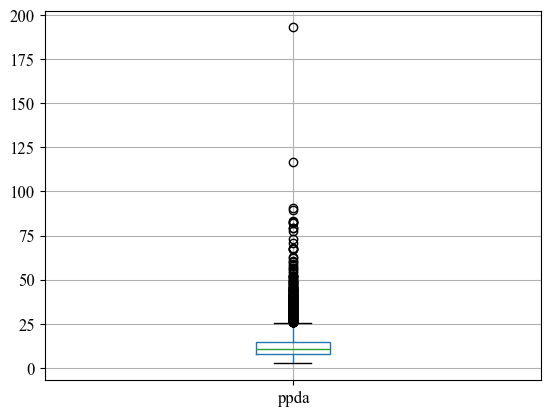

In [16]:
epl.boxplot(column=['ppda'])  # A PPDA kiugró értékei vannak, ezért mediánt fogom használni
plt.show()

In [17]:
print('50 feletti értékek száma:', (epl['ppda'] > 50).sum())

count    7600.00
mean       12.50
std         7.93
min         2.44
25%         7.70
50%        10.59
75%        14.90
max       193.00
Name: ppda, dtype: float64
50 feletti értékek száma: 33


## Új változók és a csapatok idényenkénti adatai

In [37]:
# Új változók
epl['forduló'] = epl.groupby(['season', 'club_name']).cumcount() + 1  
epl['xGD'] = epl['xG'] - epl['xGA']
epl['hazai'] = (epl['home_away'] == 'h').astype(int)                     
epl['idény'] = epl['season'].astype(str) + '/' + (epl['season'] + 1).astype(str).str[-2:]

# Csapatonként és idényenként összesítve
szezon = epl.groupby(['season', 'idény', 'club_name']).agg(
    pts=('pts', 'sum'), xpts=('xpts', 'sum'),
    scored=('scored', 'sum'), missed=('missed', 'sum'),
    xG=('xG', 'sum'), xGA=('xGA', 'sum'),
    ppda=('ppda', 'median'), deep=('deep', 'mean')).reset_index()
szezon['xGD'] = szezon['xG'] - szezon['xGA']
szezon['pont_eltérés'] = szezon['pts'] - szezon['xpts']
szezon.head()

,season,idény,club_name,pts,xpts,scored,missed,xG,xGA,ppda,deep,xGD,pont_eltérés
0,2014,2014/15,Arsenal,75,75.1740,71,36,69.802591,35.718825,8.262931,10.473684,34.083766,-0.1740
1,2014,2014/15,Aston Villa,38,40.8917,31,57,33.102671,49.706256,13.821739,4.842105,-16.603585,-2.8917
2,2014,2014/15,Burnley,33,39.7959,28,53,39.372649,57.888856,10.639310,5.736842,-18.516207,-6.7959
3,2014,2014/15,Chelsea,87,75.3172,73,32,68.643320,31.524344,10.808889,10.710526,37.118976,11.6828
4,2014,2014/15,Crystal Palace,48,50.5570,47,51,44.756683,45.484365,9.976154,4.736842,-0.727682,-2.5570


## A hazai pálya előnye

In [20]:
hazai = epl[epl['home_away'] == 'h']
print((hazai['result'].value_counts() / len(hazai) * 100).round(1))  # w = hazai győzelem, d = döntetlen, l = vendéggyőzelem
print(epl.groupby('home_away')['pts'].mean().round(2))  # átlagos pontszám mérkőzésenként (h = hazai, a = vendég)

result
w    44.9
l    31.7
d    23.3
Name: count, dtype: float64
home_away
a    1.19
h    1.58
Name: pts, dtype: float64


## 2. táblázat. A mérkőzések kimenetele idényenként

In [22]:
kimenetel = pd.crosstab(hazai['idény'], hazai['result'])
kimenetel = kimenetel[['w', 'd', 'l']]
kimenetel.columns = ['Hazai győzelem', 'Döntetlen', 'Vendéggyőzelem']
kimenetel.loc['Összesen'] = kimenetel.sum()
kimenetel['Hazai győzelmek aránya (%)'] = (kimenetel['Hazai győzelem'] / kimenetel.sum(axis=1) * 100).round(1)
kimenetel

,Hazai győzelem,Döntetlen,Vendéggyőzelem,Hazai győzelmek aránya (%)
idény,,,,
2014/15,172,93,115,45.3
2015/16,157,107,116,41.3
2016/17,187,84,109,49.2
2017/18,173,99,108,45.5
2018/19,181,71,128,47.6
2019/20,172,92,116,45.3
2020/21,144,83,153,37.9
2021/22,163,88,129,42.9
2022/23,184,87,109,48.4


## Tényleges és várható pontszám

In [27]:
print('Pontszám átlaga:', round(szezon['pts'].mean(), 1))
print('Várható pontszám átlaga:', round(szezon['xpts'].mean(), 1))
print('Átlagos abszolút eltérés:', round(szezon['pont_eltérés'].abs().mean(), 1), 'pont')
print('A 10 pontnál nagyobb eltérések aránya:', round((szezon['pont_eltérés'].abs() > 10).mean() * 100, 1), '%')

Pontszám átlaga: 52.6
Várható pontszám átlaga: 52.7
Átlagos abszolút eltérés: 6.1 pont
A 10 pontnál nagyobb eltérések aránya: 19.5 %


## A legnagyobb túl- és alulteljesítés

In [28]:
oszlopok = ['idény', 'club_name', 'pts', 'xpts', 'pont_eltérés']
print('Legnagyobb túlteljesítés:')
display(szezon.sort_values('pont_eltérés', ascending=False)[oszlopok].head(1).round(1))
print('Legnagyobb alulteljesítés:')
display(szezon.sort_values('pont_eltérés')[oszlopok].head(1).round(1))

Legnagyobb túlteljesítés:


,idény,club_name,pts,xpts,pont_eltérés
109,2019/20,Liverpool,99,74.3,24.7


Legnagyobb alulteljesítés:


,idény,club_name,pts,xpts,pont_eltérés
122,2020/21,Brighton,41,61.4,-20.4


## 1. ábra. A tényleges és a várható pontszám csapatok idényei szerint

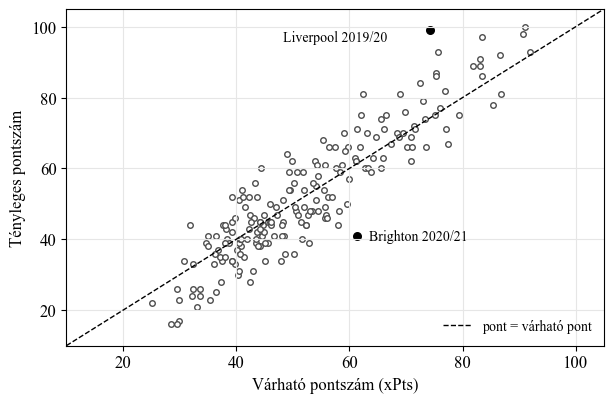

In [30]:

fig, ax = plt.subplots(figsize=(6.3, 4.2))
ax.scatter(szezon['xpts'], szezon['pts'], s=16, facecolors='white', edgecolors='0.3')
ax.plot([10, 105], [10, 105], color='black', lw=1, ls='--', label='pont = várható pont')

# Kiemelés a legnagyobb túlteljesítés 
lfc_1920 = szezon[(szezon['club_name'] == 'Liverpool') & (szezon['season'] == 2019)]
ax.scatter(lfc_1920['xpts'], lfc_1920['pts'], s=30, color='black')
ax.text(lfc_1920['xpts'].iloc[0] - 26, lfc_1920['pts'].iloc[0] - 2, 'Liverpool 2019/20', fontsize=10, va='center')

# Kiemelés a legnagyobb alulteljesítés 
bha_2021 = szezon[(szezon['club_name'] == 'Brighton') & (szezon['season'] == 2020)]
ax.scatter(bha_2021['xpts'], bha_2021['pts'], s=30, color='black')
ax.text(bha_2021['xpts'].iloc[0] + 2, bha_2021['pts'].iloc[0], 'Brighton 2020/21', fontsize=10, va='center')

ax.set_xlim(10, 105)
ax.set_ylim(10, 105)
ax.set_xlabel('Várható pontszám (xPts)')
ax.set_ylabel('Tényleges pontszám')
ax.legend(loc='lower right', fontsize=10, frameon=False)
ax.grid(color='0.9')
plt.tight_layout()
plt.show()

## 2. ábra. Az idényszintű változók korrelációs mátrixa

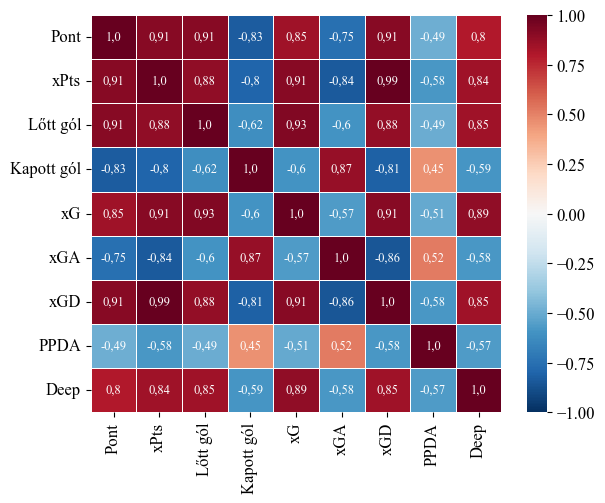

In [31]:
változók = ['pts', 'xpts', 'scored', 'missed', 'xG', 'xGA', 'xGD', 'ppda', 'deep']
nevek = ['Pont', 'xPts', 'Lőtt gól', 'Kapott gól', 'xG', 'xGA', 'xGD', 'PPDA', 'Deep']
korreláció = szezon[változók].corr()
korreláció.index = nevek
korreláció.columns = nevek

fig, ax = plt.subplots(figsize=(6.3, 5.2))
feliratok = korreláció.round(2).astype(str).replace(r'\.', ',', regex=True)
sns.heatmap(korreláció, annot=feliratok, fmt='', cmap='RdBu_r', vmin=-1, vmax=1, linewidths=0.5,
            annot_kws={'size': 9}, ax=ax)
plt.tight_layout()
plt.show()

# 4.2 Pontszám-előrejelzés az első tíz forduló alapján

In [43]:
# A magyarázó változók az első tíz fordulóból, a célváltozó a 11–38. fordulóból
első10 = epl[epl['forduló'] <= 10]
többi = epl[epl['forduló'] > 10]

# Magyarázó változók az első tíz forduló összesítve, csapatonként és idényenként
X_tábla = első10.groupby(['season', 'idény', 'club_name']).agg(
    pts_10=('pts', 'sum'), xpts_10=('xpts', 'sum'),
    scored_10=('scored', 'sum'), missed_10=('missed', 'sum'),
    xG_10=('xG', 'sum'), xGA_10=('xGA', 'sum'),
    npxG_10=('npxG', 'sum'), npxGA_10=('npxGA', 'sum'),
    ppda_10=('ppda', 'median'), ppda_allowed_10=('ppda_allowed', 'median'),
    deep_10=('deep', 'sum'), deep_allowed_10=('deep_allowed', 'sum'),
    hazai_10=('hazai', 'sum'))   # hazai mérkőzések száma

# Célváltozó a 11–38. fordulóban szerzett pontok
y_tábla = többi.groupby(['season', 'idény', 'club_name'])['pts'].sum().rename('pts_11_38')
adat = X_tábla.join(y_tábla).reset_index()
adat.head()



,season,idény,club_name,pts_10,xpts_10,scored_10,missed_10,xG_10,xGA_10,npxG_10,npxGA_10,ppda_10,ppda_allowed_10,deep_10,deep_allowed_10,hazai_10,pts_11_38
0,2014,2014/15,Arsenal,17,19.8491,18,11,18.268889,9.013514,18.268889,8.252341,7.290541,13.586207,108,38,5,58
1,2014,2014/15,Aston Villa,10,9.3637,5,16,6.757890,13.978960,6.757890,13.978960,21.519737,8.313492,33,68,5,28
2,2014,2014/15,Burnley,4,9.4806,5,19,9.103662,16.817552,8.342493,16.817552,13.145161,11.333333,53,62,5,29
3,2014,2014/15,Chelsea,26,20.9139,26,10,19.559646,8.526777,18.037303,8.526777,11.435961,13.327295,91,53,5,61
4,2014,2014/15,Crystal Palace,9,11.9748,14,19,11.283250,13.127968,9.760921,10.844492,12.808974,5.487037,34,71,5,39


In [44]:
magyarázó = ['pts_10', 'xpts_10', 'scored_10', 'missed_10', 'xG_10', 'xGA_10', 'npxG_10', 'npxGA_10',
             'ppda_10', 'ppda_allowed_10', 'deep_10', 'deep_allowed_10', 'hazai_10']
magyar_nevek = ['Szerzett pont', 'Várható pont (xPts)', 'Lőtt gól', 'Kapott gól', 'xG', 'xGA', 'npxG', 'npxGA',
                'PPDA', 'Ellenfél PPDA', 'Deep', 'Ellenfél deep', 'Hazai mérkőzések száma']

In [45]:
# Időrendi felosztás: 2014/15–2020/21 tanítóhalmaz, 2021/22–2023/24 teszthalmaz
train = adat[adat['season'] <= 2020].reset_index(drop=True)
test = adat[adat['season'] >= 2021].reset_index(drop=True)

x_train = train[magyarázó]
y_train = train['pts_11_38']
x_test = test[magyarázó]
y_test = test['pts_11_38']

print('Tanítóhalmaz:', len(train), 'megfigyelés')
print('Teszthalmaz:', len(test), 'megfigyelés')

Tanítóhalmaz: 140 megfigyelés
Teszthalmaz: 60 megfigyelés


## 3. táblázat. A magyarázó változók korrelációja a 11–38. fordulóban szerzett pontszámmal 

In [46]:
korr = train[magyarázó + ['pts_11_38']].corr()['pts_11_38'].drop('pts_11_38')
korr.index = magyar_nevek
korr.sort_values(ascending=False).round(2)

Várható pont (xPts)       0.74
Szerzett pont             0.69
xG                        0.69
npxG                      0.68
Deep                      0.66
Lőtt gól                  0.64
Ellenfél PPDA             0.58
Hazai mérkőzések száma   -0.14
PPDA                     -0.39
Kapott gól               -0.53
Ellenfél deep            -0.57
xGA                      -0.59
npxGA                    -0.61
Name: pts_11_38, dtype: float64

## Naiv előrejelzések

In [47]:
# a csapat a hátralévő 28 fordulóban ugyanolyan ütemben szerez pontot, mint az első tízben
y_pred_naiv_pont = x_test['pts_10'] / 10 * 28
y_pred_naiv_xpts = x_test['xpts_10'] / 10 * 28

In [48]:
def értékelés(név, y_valós, y_becsült, cv_mae=np.nan):
    mae = mean_absolute_error(y_valós, y_becsült)
    rmse = np.sqrt(mean_squared_error(y_valós, y_becsült))
    r2 = r2_score(y_valós, y_becsült)
    print(f'{név:<22} MAE: {mae:.2f}   RMSE: {rmse:.2f}   R²: {r2:.2f}')
    return {'Modell': név, 'CV MAE': cv_mae, 'MAE': mae, 'RMSE': rmse, 'R2': r2}

eredmények = []
eredmények.append(értékelés('Naiv (pontátlag)', y_test, y_pred_naiv_pont))
eredmények.append(értékelés('Naiv (xPts-átlag)', y_test, y_pred_naiv_xpts))

Naiv (pontátlag)       MAE: 10.13   RMSE: 13.36   R²: 0.10
Naiv (xPts-átlag)      MAE: 8.60   RMSE: 10.86   R²: 0.41


## Keresztvalidáció idősoros felosztással

In [50]:
cv_felosztás = []
for valid_idény in [2017, 2018, 2019, 2020]:
    tanító_sorok = train[train['season'] < valid_idény].index.values
    valid_sorok = train[train['season'] == valid_idény].index.values
    cv_felosztás.append((tanító_sorok, valid_sorok))

## Modellek

In [51]:
# Lineáris regresszió
lr = Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())])
grid_lr = GridSearchCV(lr, param_grid={}, cv=cv_felosztás, scoring='neg_mean_absolute_error')
grid_lr.fit(x_train, y_train)
y_pred_lr = grid_lr.predict(x_test)
eredmények.append(értékelés('Lineáris regresszió', y_test, y_pred_lr, -grid_lr.best_score_))

Lineáris regresszió    MAE: 8.46   RMSE: 10.38   R²: 0.46


In [52]:
# Ridge-regresszió
ridge = Pipeline([('scaler', StandardScaler()), ('model', Ridge())])
param_grid = {'model__alpha': np.logspace(-3, 3, 50)}
grid_ridge = GridSearchCV(ridge, param_grid=param_grid, cv=cv_felosztás, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_ridge.fit(x_train, y_train)
print('Legjobb paraméter:', grid_ridge.best_params_)
y_pred_ridge = grid_ridge.predict(x_test)
eredmények.append(értékelés('Ridge', y_test, y_pred_ridge, -grid_ridge.best_score_))

Legjobb paraméter: {'model__alpha': np.float64(59.636233165946365)}
Ridge                  MAE: 8.21   RMSE: 10.09   R²: 0.49


In [53]:
# Lasso-regresszió
lasso = Pipeline([('scaler', StandardScaler()), ('model', Lasso(max_iter=10000))])
param_grid = {'model__alpha': np.logspace(-3, 1, 50)}
grid_lasso = GridSearchCV(lasso, param_grid=param_grid, cv=cv_felosztás, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_lasso.fit(x_train, y_train)
print('Legjobb paraméter:', grid_lasso.best_params_)
y_pred_lasso = grid_lasso.predict(x_test)
eredmények.append(értékelés('Lasso', y_test, y_pred_lasso, -grid_lasso.best_score_))

Legjobb paraméter: {'model__alpha': np.float64(0.49417133613238334)}
Lasso                  MAE: 8.03   RMSE: 9.86   R²: 0.51


In [54]:
# Elastic Net
elastic = Pipeline([('scaler', StandardScaler()), ('model', ElasticNet(max_iter=10000))])
param_grid = {'model__alpha': np.logspace(-3, 1, 20), 'model__l1_ratio': np.linspace(0.1, 0.9, 9)}
grid_elastic = GridSearchCV(elastic, param_grid=param_grid, cv=cv_felosztás, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_elastic.fit(x_train, y_train)
print('Legjobb paraméterek:', grid_elastic.best_params_)
y_pred_elastic = grid_elastic.predict(x_test)
eredmények.append(értékelés('Elastic Net', y_test, y_pred_elastic, -grid_elastic.best_score_))

Legjobb paraméterek: {'model__alpha': np.float64(0.8858667904100823), 'model__l1_ratio': np.float64(0.1)}
Elastic Net            MAE: 8.21   RMSE: 10.01   R²: 0.50


In [55]:
# Random Forest
rf = RandomForestRegressor(n_estimators=300, random_state=42)
param_grid = {'max_depth': [2, 3, 5, None], 'min_samples_leaf': [1, 5, 10], 'max_features': [0.33, 0.5, 1.0]}
grid_rf = GridSearchCV(rf, param_grid=param_grid, cv=cv_felosztás, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_rf.fit(x_train, y_train)
print('Legjobb paraméterek:', grid_rf.best_params_)
y_pred_rf = grid_rf.predict(x_test)
eredmények.append(értékelés('Random Forest', y_test, y_pred_rf, -grid_rf.best_score_))

Legjobb paraméterek: {'max_depth': 2, 'max_features': 0.33, 'min_samples_leaf': 1}
Random Forest          MAE: 8.35   RMSE: 10.17   R²: 0.48


In [59]:
# XGBoost
xgb = XGBRegressor(random_state=42)
param_grid = {'n_estimators': [50, 100, 300], 'max_depth': [1, 2, 3], 'learning_rate': [0.01, 0.03, 0.1],
              'subsample': [0.8, 1.0]}
grid_xgb = GridSearchCV(xgb, param_grid=param_grid, cv=cv_felosztás, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_xgb.fit(x_train, y_train)
print('Legjobb paraméterek:', grid_xgb.best_params_)
y_pred_xgb = grid_xgb.predict(x_test)
eredmények.append(értékelés('XGBoost', y_test, y_pred_xgb, -grid_xgb.best_score_))

Legjobb paraméterek: {'learning_rate': 0.01, 'max_depth': 1, 'n_estimators': 300, 'subsample': 0.8}
XGBoost                MAE: 8.31   RMSE: 10.10   R²: 0.49


## 4. táblázat. A modellek előrejelzési hibája

In [66]:
eredmény_tábla = pd.DataFrame(eredmények).drop_duplicates('Modell', keep='last').sort_values('MAE')  
eredmény_tábla.round(2)

,Modell,CV MAE,MAE,RMSE,R2
4,Lasso,7.71,8.03,9.86,0.51
5,Elastic Net,7.59,8.21,10.01,0.50
3,Ridge,7.61,8.21,10.09,0.49
10,XGBoost,8.02,8.31,10.10,0.49
6,Random Forest,7.86,8.35,10.17,0.48
2,Lineáris regresszió,8.77,8.46,10.38,0.46
1,Naiv (xPts-átlag),NaN,8.60,10.86,0.41
0,Naiv (pontátlag),NaN,10.13,13.36,0.10


In [61]:
# A végleges modell a legkisebb keresztvalidációs hibájú 
mae_elastic = mean_absolute_error(y_test, y_pred_elastic)
mae_naiv_pont = mean_absolute_error(y_test, y_pred_naiv_pont)
mae_naiv_xpts = mean_absolute_error(y_test, y_pred_naiv_xpts)
print(f'Javulás a pontátlagos naiv előrejelzéshez képest: {(1 - mae_elastic / mae_naiv_pont) * 100:.1f}%')
print(f'Javulás az xPts-átlagos naiv előrejelzéshez képest: {(1 - mae_elastic / mae_naiv_xpts) * 100:.1f}%')

Javulás a pontátlagos naiv előrejelzéshez képest: 19.0%
Javulás az xPts-átlagos naiv előrejelzéshez képest: 4.6%


## 3. ábra. A modellek átlagos abszolút hibája a teszthalmazon

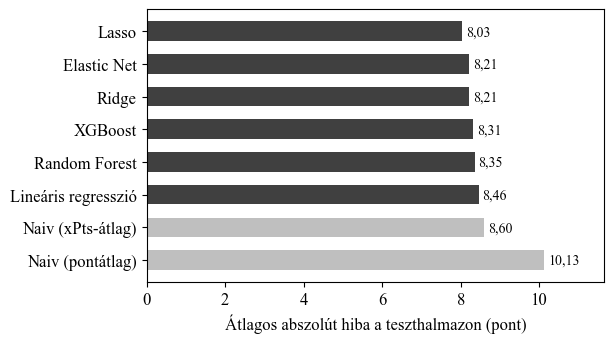

In [67]:
rajz = eredmény_tábla.sort_values('MAE', ascending=False)
színek = ['0.75', '0.75', '0.25', '0.25', '0.25', '0.25', '0.25', '0.25']   

plt.figure(figsize=(6.3, 3.6))
plt.barh(rajz['Modell'], rajz['MAE'], color=színek, height=0.6)
for i, v in enumerate(rajz['MAE']):
    plt.text(v + 0.1, i, f'{v:.2f}'.replace('.', ','), va='center', fontsize=10)
plt.xlabel('Átlagos abszolút hiba a teszthalmazon (pont)')
plt.xlim(0, rajz['MAE'].max() * 1.15)
plt.gca().xaxis.set_major_formatter(tizedesvessző)
plt.tight_layout()
plt.show()

## 5. táblázat. A lineáris modellek standardizált együtthatói 

In [69]:
együtthatók = pd.DataFrame({
    'Lineáris regresszió': grid_lr.best_estimator_.named_steps['model'].coef_,
    'Ridge': grid_ridge.best_estimator_.named_steps['model'].coef_,
    'Lasso': grid_lasso.best_estimator_.named_steps['model'].coef_,
    'Elastic Net': grid_elastic.best_estimator_.named_steps['model'].coef_}, index=magyar_nevek)
együtthatók.round(2) + 0.0

,Lineáris regresszió,Ridge,Lasso,Elastic Net
Szerzett pont,1.91,1.54,2.78,1.31
Várható pont (xPts),10.28,1.45,4.47,1.25
Lőtt gól,0.60,0.78,0.00,0.85
Kapott gól,-1.56,-0.84,-0.18,-0.78
xG,-6.39,0.95,0.00,0.98
xGA,5.31,-0.56,0.00,-0.64
npxG,1.98,0.93,0.00,0.96
npxGA,-2.39,-0.81,-0.07,-0.78
PPDA,0.48,-0.08,0.00,-0.17
Ellenfél PPDA,1.88,1.29,1.56,1.12


## 4. ábra. A magyarázó változók fontossága a Random Forest modellben

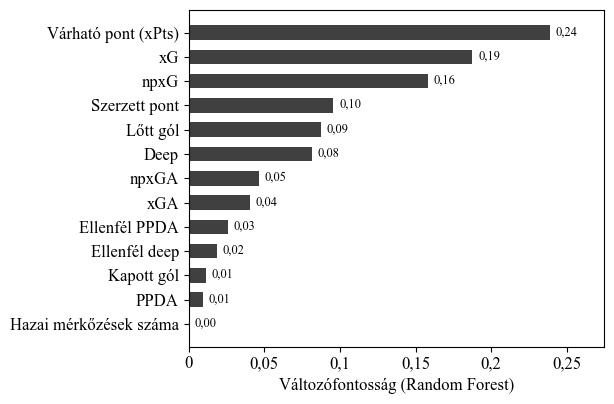

In [70]:
fontosság = pd.Series(grid_rf.best_estimator_.feature_importances_, index=magyar_nevek).sort_values()

plt.figure(figsize=(6.3, 4.2))
plt.barh(fontosság.index, fontosság.values, color='0.25', height=0.6)
for i, v in enumerate(fontosság.values):
    plt.text(v + 0.004, i, f'{v:.2f}'.replace('.', ','), va='center', fontsize=9)
plt.xlim(0, fontosság.max() * 1.15)
plt.xlabel('Változófontosság (Random Forest)')
plt.gca().xaxis.set_major_formatter(tizedesvessző)
plt.tight_layout()
plt.show()

## A legnagyobb hibák az Elastic Net modellnél

In [72]:
# Az Elastic Net becslései és hibái a teszthalmazon, csapatonként
összevető = test[['idény', 'club_name', 'pts_11_38']].copy()
összevető['becslés'] = y_pred_elastic
összevető['hiba'] = összevető['pts_11_38'] - összevető['becslés']

# A legnagyobb tévedések
print('Legnagyobb alulbecslések (a csapat többet szerzett):')
display(összevető.sort_values('hiba', ascending=False).head(2).round(1))
print('Legnagyobb felülbecslés (a csapat kevesebbet szerzett):')
display(összevető.sort_values('hiba').head(1).round(1))

Legnagyobb alulbecslések (a csapat többet szerzett):


,idény,club_name,pts_11_38,becslés,hiba
16,2021/22,Tottenham,56,33.6,22.4
13,2021/22,Newcastle United,45,26.3,18.7


Legnagyobb felülbecslés (a csapat kevesebbet szerzett):


,idény,club_name,pts_11_38,becslés,hiba
25,2022/23,Chelsea,24,45.8,-21.8


## 5. ábra. A becsült és a tényleges pontszám a teszthalmazon

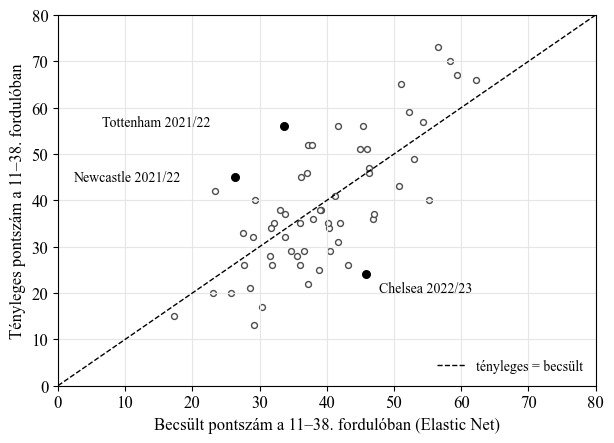

In [74]:
plt.figure(figsize=(6.3, 4.6))
plt.scatter(összevető['becslés'], összevető['pts_11_38'], s=18, facecolors='white', edgecolors='0.3')
plt.plot([0, 80], [0, 80], color='black', lw=1, ls='--', label='tényleges = becsült')

che = összevető[(összevető['club_name'] == 'Chelsea') & (összevető['idény'] == '2022/23')]
plt.scatter(che['becslés'], che['pts_11_38'], s=30, color='black')
plt.text(che['becslés'].iloc[0] + 2, che['pts_11_38'].iloc[0] - 3, 'Chelsea 2022/23', fontsize=10, va='center')

tot = összevető[(összevető['club_name'] == 'Tottenham') & (összevető['idény'] == '2021/22')]
plt.scatter(tot['becslés'], tot['pts_11_38'], s=30, color='black')
plt.text(tot['becslés'].iloc[0] - 27, tot['pts_11_38'].iloc[0] + 1, 'Tottenham 2021/22', fontsize=10, va='center')

new = összevető[(összevető['club_name'] == 'Newcastle United') & (összevető['idény'] == '2021/22')]
plt.scatter(new['becslés'], new['pts_11_38'], s=30, color='black')
plt.text(new['becslés'].iloc[0] - 24, new['pts_11_38'].iloc[0], 'Newcastle 2021/22', fontsize=10, va='center')

plt.xlim(0, 80)
plt.ylim(0, 80)
plt.xlabel('Becsült pontszám a 11–38. fordulóban (Elastic Net)')
plt.ylabel('Tényleges pontszám a 11–38. fordulóban')
plt.legend(loc='lower right', fontsize=10, frameon=False)
plt.grid(color='0.9')
plt.tight_layout()
plt.show()

# 4.3 A Liverpool teljesítményének idősora

In [75]:
lfc = epl[epl['club_name'] == 'Liverpool'].sort_values('date').reset_index(drop=True)
lfc['meccs'] = np.arange(1, len(lfc) + 1)   # a mérkőzések sorszáma 1-től 380-ig
lfc.head()

,id,league,season,club_name,home_away,xG,xGA,npxG,npxGA,ppda,...,wins,draws,loses,pts,npxGD,forduló,xGD,idény,hazai,meccs
0,87,EPL,2014,Liverpool,h,1.331920,1.552480,1.331920,1.552480,11.333333,...,1,0,0,3,-0.220560,1,-0.220560,2014/15,1,1
1,87,EPL,2014,Liverpool,a,0.901889,1.313750,0.901889,1.313750,18.222222,...,0,0,1,0,-0.411861,2,-0.411861,2014/15,0,2
2,87,EPL,2014,Liverpool,a,2.743170,0.485920,1.982000,0.485920,12.120000,...,1,0,0,3,1.496080,3,2.257250,2014/15,0,3
3,87,EPL,2014,Liverpool,h,0.728097,0.701676,0.728097,0.701676,6.500000,...,0,0,1,0,0.026421,4,0.026421,2014/15,1,4
4,87,EPL,2014,Liverpool,a,0.378350,1.260320,0.378350,1.260320,7.176471,...,0,0,1,0,-0.881970,5,-0.881970,2014/15,0,5


## 6. ábra. A Liverpool teljesítménye mérkőzésenként

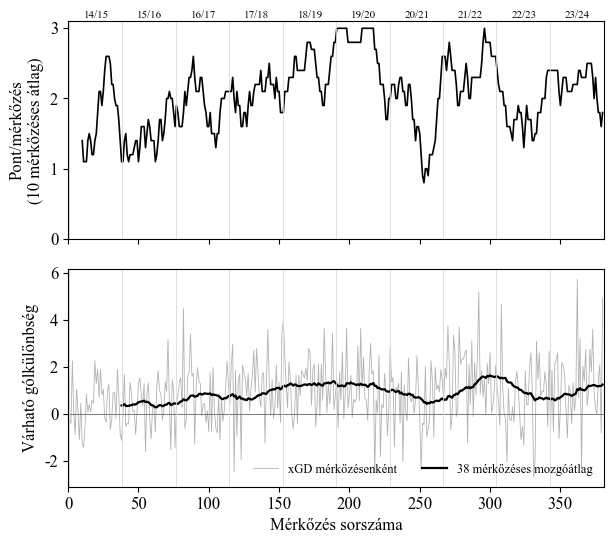

In [78]:
idény_kezdetek = lfc.groupby('idény')['meccs'].min() 

fig, axes = plt.subplots(2, 1, figsize=(6.3, 5.6), sharex=True)

# tízmérkőzéses mozgó pontátlag
axes[0].plot(lfc['meccs'], lfc['pts'].rolling(10).mean(), color='black', lw=1.2)
axes[0].set_ylabel('Pont/mérkőzés\n(10 mérkőzéses átlag)')
axes[0].set_ylim(0, 3.1)
for idény, kezdet in idény_kezdetek.items():
    axes[0].text(kezdet + 19, 3.12, idény[2:], ha='center', va='bottom', fontsize=8)  

# xGD mérkőzésenként és a 38 mérkőzéses mozgóátlag
axes[1].plot(lfc['meccs'], lfc['xGD'], color='0.7', lw=0.6, label='xGD mérkőzésenként')
axes[1].plot(lfc['meccs'], lfc['xGD'].rolling(38).mean(), color='black', lw=1.6, label='38 mérkőzéses mozgóátlag')
axes[1].axhline(0, color='0.4', lw=0.6)
axes[1].set_ylabel('Várható gólkülönbség')
axes[1].set_xlabel('Mérkőzés sorszáma')
axes[1].set_xlim(0, 381)
axes[1].legend(loc='lower right', fontsize=9, frameon=False, ncol=2)

for kezdet in idény_kezdetek:
    axes[0].axvline(kezdet - 0.5, color='0.85', lw=0.6)
    axes[1].axvline(kezdet - 0.5, color='0.85', lw=0.6)

axes[0].yaxis.set_major_formatter(tizedesvessző)
axes[1].yaxis.set_major_formatter(tizedesvessző)

plt.tight_layout()
plt.show()

## 6. táblázat. A Liverpool eredményei idényenként

In [79]:
liverpool_idények = lfc.groupby('idény').agg(Pont=('pts', 'sum'), Pont_mérkőzés=('pts', 'mean'), xGD=('xGD', 'mean'))
liverpool_idények.columns = ['Pont', 'Pont/mérkőzés', 'xGD átlaga']
liverpool_idények.round(2)

,Pont,Pont/mérkőzés,xGD átlaga
idény,,,
2014/15,62,1.63,0.35
2015/16,60,1.58,0.43
2016/17,76,2.00,0.76
2017/18,75,1.97,1.10
2018/19,97,2.55,1.32
2019/20,99,2.61,0.94
2020/21,69,1.82,0.66
2021/22,92,2.42,1.59
2022/23,67,1.76,0.66


In [80]:
# Tanítóhalmaz: 2014/15–2022/23, teszthalmaz: 2023/24
lfc_train = lfc[lfc['season'] <= 2022].reset_index(drop=True)
lfc_test = lfc[lfc['season'] == 2023].reset_index(drop=True)

print('Tanító elemszám:', len(lfc_train))
print('Teszt elemszám:', len(lfc_test))
print('Átlagos xGD a tanítóhalmazon:', round(lfc_train['xGD'].mean(), 2))
print('Átlagos xGD a teszthalmazon:', round(lfc_test['xGD'].mean(), 2))

Tanító elemszám: 342
Teszt elemszám: 38
Átlagos xGD a tanítóhalmazon: 0.87
Átlagos xGD a teszthalmazon: 1.25


## 7. ábra. A Liverpool xGD-idősorának additív dekompozíciója a tanítóhalmazon, 2014/15-2022/23

In [82]:
decomp = seasonal_decompose(lfc_train['xGD'], model='additive', period=38)  

print('Az eredeti sor szórása:', round(lfc_train['xGD'].std(), 2))
print('Trendciklus szórása:', round(decomp.trend.std(), 2))
print('Szezonális komponens szórása:', round(decomp.seasonal.std(), 2))
print('Maradékkomponens szórása:', round(decomp.resid.std(), 2))

Az eredeti sor szórása: 1.31
Trendciklus szórása: 0.34
Szezonális komponens szórása: 0.37
Maradékkomponens szórása: 1.18


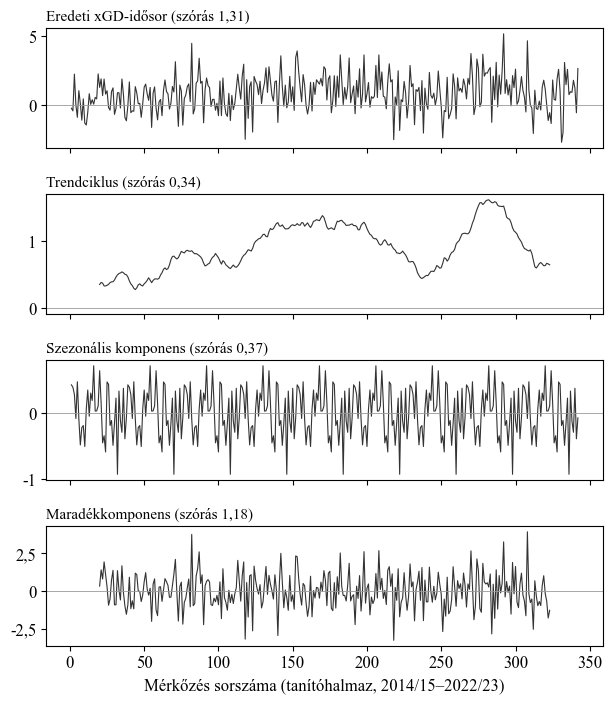

In [83]:
sorszám = np.arange(1, len(lfc_train) + 1)   

fig, axes = plt.subplots(4, 1, figsize=(6.3, 7.2), sharex=True)   

# Eredeti idősor
axes[0].plot(sorszám, lfc_train['xGD'], color='0.2', lw=0.8)
axes[0].set_title('Eredeti xGD-idősor (szórás 1,31)', fontsize=11, loc='left')

# Trendciklus
axes[1].plot(sorszám, decomp.trend, color='0.2', lw=0.8)
axes[1].set_title('Trendciklus (szórás 0,34)', fontsize=11, loc='left')

# Szezonális komponens
axes[2].plot(sorszám, decomp.seasonal, color='0.2', lw=0.8)
axes[2].set_title('Szezonális komponens (szórás 0,37)', fontsize=11, loc='left')

# Maradékkomponens
axes[3].plot(sorszám, decomp.resid, color='0.2', lw=0.8)
axes[3].set_title('Maradékkomponens (szórás 1,18)', fontsize=11, loc='left')
axes[3].set_xlabel('Mérkőzés sorszáma (tanítóhalmaz, 2014/15–2022/23)')

# Nullvonal mind a négy részen
axes[0].axhline(0, color='0.6', lw=0.6)
axes[1].axhline(0, color='0.6', lw=0.6)
axes[2].axhline(0, color='0.6', lw=0.6)
axes[3].axhline(0, color='0.6', lw=0.6)

# Tizedesvessző a függőleges tengelyeken
axes[0].yaxis.set_major_formatter(tizedesvessző)
axes[1].yaxis.set_major_formatter(tizedesvessző)
axes[2].yaxis.set_major_formatter(tizedesvessző)
axes[3].yaxis.set_major_formatter(tizedesvessző)

plt.tight_layout()
plt.show()

## Stacionaritás: ADF- és KPSS-próba

In [87]:
def adf_report(series, title="Idősor"):
    series = series.dropna()
    result = adfuller(series)
    print(f"ADF-próba – {title}")
    print(f"ADF statisztika: {result[0]:.4f}")
    print(f"p-érték:        {result[1]:.6f}")
    print(f"Késleltetés:    {result[2]}")
    print(f"Megfigyelések:  {result[3]}")
    print("Kritikus értékek:")
    for key, value in result[4].items():
        print(f"  {key}: {value:.4f}")
    if result[1] < 0.05:
        print("\nÉrtelmezés: a sor stacionáriusnak tekinthető 5%-os szinten.")
    else:
        print("\nÉrtelmezés: a sor nem tekinthető stacionáriusnak 5%-os szinten.")
    print("-" * 50)

In [88]:
def kpss_report(series, title="Idősor"):
    series = series.dropna()
    result = kpss(series, regression="c", nlags="auto")
    print(f"KPSS-próba – {title}")
    print(f"KPSS statisztika: {result[0]:.4f}")
    print(f"p-érték:         {result[1]:.4f}")  
    print(f"Késleltetés:     {result[2]}")
    print("Kritikus értékek:")
    for key, value in result[3].items():
        print(f"  {key}: {value:.4f}")
    if result[1] < 0.05:
        print("\nÉrtelmezés: a sor nem tekinthető stacionáriusnak 5%-os szinten.")
    else:
        print("\nÉrtelmezés: a sor stacionáriusnak tekinthető 5%-os szinten.")
    print("-" * 50)

In [105]:
adf_report(lfc_train['xGD'], 'xGD')
kpss_report(lfc_train['xGD'], 'xGD')

ADF-próba – xGD
ADF statisztika: -6.1958
p-érték:        0.000000
Késleltetés:    4
Megfigyelések:  337
Kritikus értékek:
  1%: -3.4499
  5%: -2.8702
  10%: -2.5714

Értelmezés: a sor stacionáriusnak tekinthető 5%-os szinten.
--------------------------------------------------
KPSS-próba – xGD
KPSS statisztika: 0.7743
p-érték:         0.0100
Késleltetés:     3
Kritikus értékek:
  10%: 0.3470
  5%: 0.4630
  2.5%: 0.5740
  1%: 0.7390

Értelmezés: a sor nem tekinthető stacionáriusnak 5%-os szinten.
--------------------------------------------------


In [106]:
adf_report(lfc_train['xGD'].diff(), 'xGD első differenciája')
kpss_report(lfc_train['xGD'].diff(), 'xGD első differenciája')

ADF-próba – xGD első differenciája
ADF statisztika: -10.1755
p-érték:        0.000000
Késleltetés:    9
Megfigyelések:  331
Kritikus értékek:
  1%: -3.4503
  5%: -2.8703
  10%: -2.5714

Értelmezés: a sor stacionáriusnak tekinthető 5%-os szinten.
--------------------------------------------------
KPSS-próba – xGD első differenciája
KPSS statisztika: 0.0710
p-érték:         0.1000
Késleltetés:     41
Kritikus értékek:
  10%: 0.3470
  5%: 0.4630
  2.5%: 0.5740
  1%: 0.7390

Értelmezés: a sor stacionáriusnak tekinthető 5%-os szinten.
--------------------------------------------------


## 8. ábra. A Liverpool xGD-idősorának ACF- és PACF-függvénye

A konfidenciasáv határa: ± 0.11


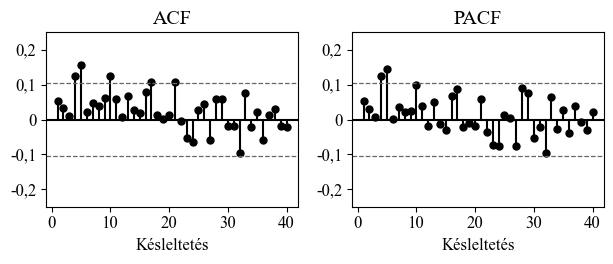

In [92]:
határ = 1.96 / np.sqrt(len(lfc_train))   # a 95%-os konfidenciasáv határa (±1,96/√342)
print('A konfidenciasáv határa: ±', round(határ, 2))

fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.8))
plot_acf(lfc_train['xGD'], lags=40, ax=axes[0], zero=False, alpha=None, color='black', vlines_kwargs={'colors': 'black'})
plot_pacf(lfc_train['xGD'], lags=40, ax=axes[1], zero=False, alpha=None, method='ywm', color='black', vlines_kwargs={'colors': 'black'})
axes[0].set_title('ACF')
axes[1].set_title('PACF')

# A konfidenciasáv határai szaggatott vonallal
axes[0].axhline(határ, color='0.4', ls='--', lw=0.9)
axes[0].axhline(-határ, color='0.4', ls='--', lw=0.9)
axes[1].axhline(határ, color='0.4', ls='--', lw=0.9)
axes[1].axhline(-határ, color='0.4', ls='--', lw=0.9)

axes[0].set_xlabel('Késleltetés')
axes[1].set_xlabel('Késleltetés')
axes[0].set_ylim(-0.25, 0.25)
axes[1].set_ylim(-0.25, 0.25)
axes[0].yaxis.set_major_formatter(tizedesvessző)
axes[1].yaxis.set_major_formatter(tizedesvessző)

plt.tight_layout()
plt.show()

## ARIMA-modellek összehasonlítása AIC alapján

In [93]:
candidate_orders = [(0, 0, 0), (0, 0, 1), (0, 0, 2), (1, 0, 0), (1, 0, 1), (1, 0, 2), (2, 0, 0), (2, 0, 1), (2, 0, 2),
                    (0, 1, 0), (0, 1, 1), (0, 1, 2), (1, 1, 0), (1, 1, 1), (1, 1, 2), (2, 1, 0), (2, 1, 1), (2, 1, 2)]

results = []

for order in candidate_orders:
    model = ARIMA(lfc_train['xGD'], order=order)
    fitted = model.fit()

    results.append({
        'order': order,
        'd': order[1],
        'AIC': fitted.aic
    })

results_df = pd.DataFrame(results).sort_values(by=['d', 'AIC'])  
results_df.round(1)

,order,d,AIC
4,"(1, 0, 1)",0,1153.1
7,"(2, 0, 1)",0,1154.8
8,"(2, 0, 2)",0,1154.9
0,"(0, 0, 0)",0,1158.4
3,"(1, 0, 0)",0,1159.5
1,"(0, 0, 1)",0,1159.5
6,"(2, 0, 0)",0,1161.1
2,"(0, 0, 2)",0,1161.2
5,"(1, 0, 2)",0,1163.0
10,"(0, 1, 1)",1,1152.5


In [94]:
d1_modellek = results_df[results_df['d'] == 1]
best_order = tuple(d1_modellek.iloc[0]['order'])
print('Kiválasztott rend:', best_order)

best_model = ARIMA(lfc_train['xGD'], order=best_order)
best_fitted = best_model.fit()

print(best_fitted.summary())

Kiválasztott rend: (0, 1, 1)
                               SARIMAX Results                                
Dep. Variable:                    xGD   No. Observations:                  342
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -574.239
Date:                Thu, 12 Nov 2026   AIC                           1152.478
Time:                        00:52:45   BIC                           1160.142
Sample:                             0   HQIC                          1155.531
                                - 342                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9508      0.017    -55.756      0.000      -0.984      -0.917
sigma2         1.6874      0.126     13.360      0.000       1.440       1.935
Ljung-Box (L1) (Q):    

In [95]:
# A kiválasztott modell reziduumai
residuals = best_fitted.resid.iloc[1:]

# Ljung–Box-próba
ljung_box = acorr_ljungbox(residuals, lags=[10, 20], model_df=1, return_df=True)
ljung_box.round(3)

,lb_stat,lb_pvalue
10,9.767,0.370
20,14.445,0.757


In [96]:
# Egyszerű exponenciális simítás 
ses_model = SimpleExpSmoothing(lfc_train['xGD'], initialization_method='estimated')
ses_fitted = ses_model.fit() 

alpha = ses_fitted.params['smoothing_level']
print('Simítási paraméter (α):', round(alpha, 3))

Simítási paraméter (α): 0.043


## Gördülő, egylépéses előrejelzés a 2023/24-es idényre


In [97]:
y = lfc['xGD'].values
pálya = lfc['hazai'].values         # 1 = hazai, 0 = idegenbeli mérkőzés
x_hazai = lfc[['hazai']].values     # külső változó a dinamikus regresszióhoz
kezdet = len(lfc_train)             # az első tesztmérkőzés sorszáma

naiv, eddigi_átlag, mozgóátlag, simítás = [], [], [], []
arima_011, arima_101, dinamikus = [], [], []
eddigi_pálya, utolsó38_pálya = [], []

for t in range(kezdet, len(lfc)):
    múltbeli = y[:t]   
    naiv.append(múltbeli[-1])
    eddigi_átlag.append(múltbeli.mean())
    mozgóátlag.append(múltbeli[-38:].mean())
    simítás.append(SimpleExpSmoothing(múltbeli, initialization_method='estimated').fit().forecast(1)[0])
    arima_011.append(ARIMA(múltbeli, order=(0, 1, 1)).fit().forecast(1)[0])
    arima_101.append(ARIMA(múltbeli, order=(1, 0, 1)).fit().forecast(1)[0])
    din_modell = ARIMA(múltbeli, exog=x_hazai[:t], order=(0, 1, 1)).fit()
    dinamikus.append(din_modell.forecast(1, exog=x_hazai[t:t + 1])[0])
    eddigi_pálya.append(múltbeli[pálya[:t] == pálya[t]].mean())
    utolsó38 = múltbeli[-38:]
    utolsó38_pálya.append(utolsó38[pálya[t - 38:t] == pálya[t]].mean())

## 7. táblázat. Az idősoros modellek előrejelzési hibája a 2023/24-es idényben

In [99]:
valós = lfc_test['xGD'].values
előrejelzések = {'Naiv': naiv,
                 'Eddigi átlag': eddigi_átlag,
                 'Mozgóátlag (38 mérkőzés)': mozgóátlag,
                 'Exponenciális simítás': simítás,
                 'ARIMA(0,1,1)': arima_011,
                 'ARIMA(1,0,1)': arima_101,
                 'Dinamikus regresszió (ARIMA(0,1,1) + hazai pálya)': dinamikus,
                 'Eddigi hazai/idegenbeli átlag*': eddigi_pálya,
                 'Utolsó 38 mérkőzés hazai/idegenbeli átlaga*': utolsó38_pálya}

results_ts = []
for név, becslés in előrejelzések.items():
    mae = mean_absolute_error(valós, becslés)
    rmse = np.sqrt(mean_squared_error(valós, becslés))
    results_ts.append({'Modell': név, 'MAE': mae, 'RMSE': rmse})

results_ts_df = pd.DataFrame(results_ts).sort_values('MAE')
results_ts_df.round(2)

,Modell,MAE,RMSE
8,Utolsó 38 mérkőzés hazai/idegenbeli átlaga*,1.08,1.40
7,Eddigi hazai/idegenbeli átlag*,1.14,1.50
6,"Dinamikus regresszió (ARIMA(0,1,1) + hazai pálya)",1.15,1.49
1,Eddigi átlag,1.30,1.67
2,Mozgóátlag (38 mérkőzés),1.31,1.66
3,Exponenciális simítás,1.31,1.67
4,"ARIMA(0,1,1)",1.32,1.67
5,"ARIMA(1,0,1)",1.32,1.68
0,Naiv,2.00,2.52


In [100]:
mae_simítás = mean_absolute_error(valós, simítás)
mae_dinamikus = mean_absolute_error(valós, dinamikus)
print(f'A dinamikus regresszió hibája {(mae_simítás - mae_dinamikus) / mae_simítás * 100:.1f}%-kal kisebb az exponenciális simításénál.')

A dinamikus regresszió hibája 12.3%-kal kisebb az exponenciális simításénál.


## 8. táblázat. A Liverpool átlagos xGD-je hazai és idegenbeli mérkőzéseken

In [102]:
train_hazai = lfc_train[lfc_train['hazai'] == 1]['xGD'].mean()     # tanítóidőszak, hazai
train_idegen = lfc_train[lfc_train['hazai'] == 0]['xGD'].mean()    # tanítóidőszak, idegenbeli
test_hazai = lfc_test[lfc_test['hazai'] == 1]['xGD'].mean()        # tesztidény, hazai
test_idegen = lfc_test[lfc_test['hazai'] == 0]['xGD'].mean()       # tesztidény, idegenbeli

hazai_idegen = pd.DataFrame({
    'Hazai': [train_hazai, test_hazai],
    'Idegenbeli': [train_idegen, test_idegen]},
    index=['Tanítóidőszak (2014/15–2022/23)', 'Tesztidény (2023/24)'])

hazai_idegen['Különbség'] = hazai_idegen['Hazai'] - hazai_idegen['Idegenbeli']
hazai_idegen.round(2)

,Hazai,Idegenbeli,Különbség
Tanítóidőszak (2014/15–2022/23),1.23,0.50,0.73
Tesztidény (2023/24),2.14,0.35,1.80


## 9. ábra. Egylépéses előrejelzések a 2023/24-es idényre

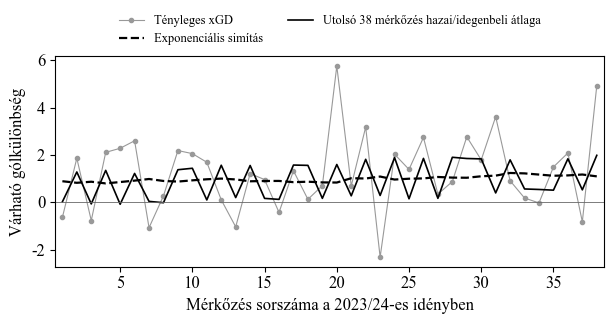

In [104]:
sorszám = np.arange(1, len(lfc_test) + 1)

plt.figure(figsize=(6.3, 3.4))
plt.plot(sorszám, valós, color='0.6', lw=0.8, marker='o', ms=3, label='Tényleges xGD')
plt.plot(sorszám, simítás, color='black', lw=1.6, ls='--', label='Exponenciális simítás')
plt.plot(sorszám, utolsó38_pálya, color='black', lw=1.2, label='Utolsó 38 mérkőzés hazai/idegenbeli átlaga')
plt.axhline(0, color='0.4', lw=0.6)
plt.xlabel('Mérkőzés sorszáma a 2023/24-es idényben')
plt.ylabel('Várható gólkülönbség')
plt.xlim(0.5, 38.5)
plt.gca().yaxis.set_major_formatter(tizedesvessző)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), fontsize=9, frameon=False, ncol=2)
plt.tight_layout()
plt.show()